In [40]:
import fastf1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

fastf1.Cache.enable_cache('../cache')
fastf1.set_log_level('WARNING')

c:\Users\Ryan\Documents\f1-lapsim\.venv\Lib\site-packages\fastf1\req.py:251: FutureWarning: `.enable_cache` is deprecated and will be removed in a future version. Use `.configure` instead.
  warnings.warn("`.enable_cache` is deprecated and will be removed in a "


In [41]:
# =================================
# Silverstone 2022 had a wet qualifying,
# which doesn't help the dry grip model.
# 
# Screening for dry conditions and races
# with minimal disruptions for the model.
# =================================

def screen(year, gp):
    q = fastf1.get_session(year, gp, 'Q')
    q.load(telemetry=False, messages=False)
    fl = q.laps.pick_fastest()
    print(f"{year} {gp} Q: {fl['Driver']} {fl['LapTime']} {fl['Compound']}, "
          f"rain during Q: {q.weather_data['Rainfall'].any()}")

    r = fastf1.get_session(year, gp, 'R')
    r.load(telemetry=False, messages=False)
    print(r.track_status['Message'].value_counts(), '\n')


screen(2022, 'Spain')

2022 Spain Q: LEC 0 days 00:01:18.750000 SOFT, rain during Q: False
Message
Yellow      4
AllClear    4
Name: count, dtype: int64 



In [42]:
session = fastf1.get_session(2022, 'Spain', 'Q')
session.load()

lap = session.laps.pick_fastest()
print(lap['Driver'], lap['LapTime'])

LEC 0 days 00:01:18.750000


In [43]:
pos = lap.get_pos_data()
tel = lap.get_telemetry()    # Car data and position, merged and interpolated

print('pos rows:', len(pos))
print('tel rows:', len(tel))
print(pos.columns.tolist())
pos.head()

pos rows: 300
tel rows: 608
['Date', 'Status', 'X', 'Y', 'Z', 'Source', 'Time', 'SessionTime']


,Date,Status,X,Y,Z,Source,Time,SessionTime
0,2022-05-21 14:58:14.918,OnTrack,756.0,-577.0,1707.0,pos,0 days 00:00:00.160000,0 days 01:13:14.905000
1,2022-05-21 14:58:15.218,OnTrack,627.0,-781.0,1708.0,pos,0 days 00:00:00.460000,0 days 01:13:15.205000
2,2022-05-21 14:58:15.298,OnTrack,592.0,-836.0,1708.0,pos,0 days 00:00:00.540000,0 days 01:13:15.285000
3,2022-05-21 14:58:15.598,OnTrack,400.0,-1138.0,1708.0,pos,0 days 00:00:00.840000,0 days 01:13:15.585000
4,2022-05-21 14:58:16.058,OnTrack,259.0,-1361.0,1708.0,pos,0 days 00:00:01.300000,0 days 01:13:16.045000


In [44]:
# =================================
# Verifying the distance units
# =================================

x_raw = pos['X'].to_numpy()
y_raw = pos['Y'].to_numpy()

dx = np.diff(x_raw)
dy = np.diff(y_raw)
step = np.hypot(dx, dy)        # length of each segment 
path_length_raw = step.sum()

print('Raw path length:', path_length_raw)
print('FastF1 Distance channel, end of lap:', tel['Distance'].iloc[-1], 'metres')

# =================================
# Because the ratio is 10 the data is in decimetres
# =================================

Raw path length: 45850.36019287912
FastF1 Distance channel, end of lap: 4636.771676129172 metres


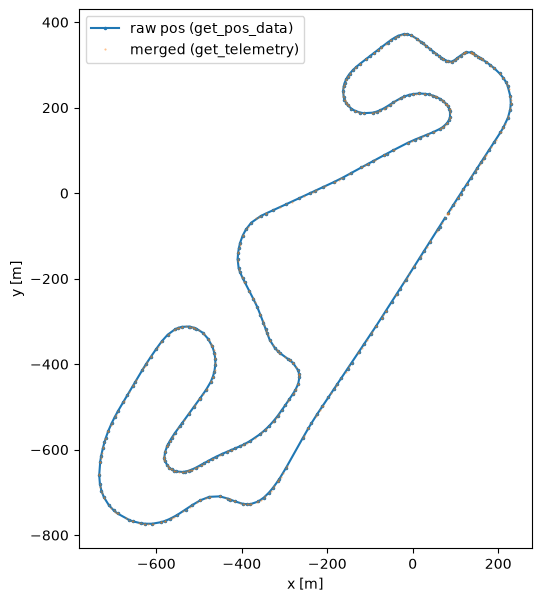

In [45]:
# =================================
# A check to see the data looks right
# =================================

x = x_raw / 10.0
y = y_raw / 10.0

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(x, y, '.-', markersize=3, label='raw pos (get_pos_data)')
ax.plot(tel['X'] / 10, tel['Y'] / 10, '.', markersize=1, alpha=0.5, label='merged (get_telemetry)')
ax.set_aspect('equal')
ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
ax.legend()
plt.show()

In [46]:
# =================================
# Arc length
# =================================

x = pos['X'].to_numpy() / 10.0    
y = pos['Y'].to_numpy() / 10.0

seg = np.hypot(np.diff(x), np.diff(y))          # segment length
s = np.concatenate(([0.0], np.cumsum(seg)))     # arc length at each sample

print('samples:', len(x), ' s values:', len(s))
print('lap length from s:', s[-1], 'm')
print('segment length min / mean / max:', seg.min(), seg.mean(), seg.max())
print('zero-length segments:', (seg == 0).sum())

samples: 300  s values: 300
lap length from s: 4585.036019287911 m
segment length min / mean / max: 1.3601470508735234 15.334568626380978 79.2480283666414
zero-length segments: 0


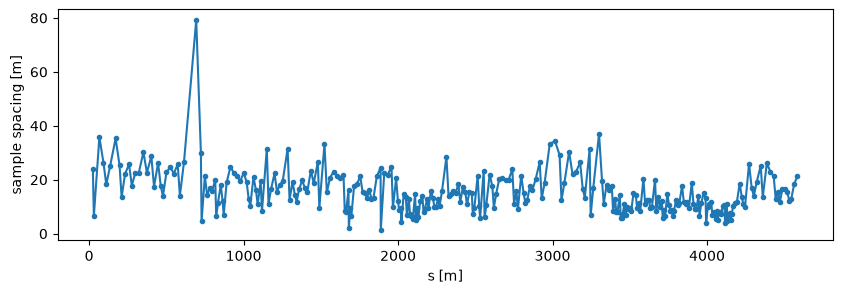

In [47]:
# =================================
# Sample spacing
# =================================

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(s[1:], seg, '.-')
ax.set_xlabel('s [m]'); ax.set_ylabel('sample spacing [m]')
plt.show()

In [48]:
# =================================
# Resample
# =================================

ds = 2.0                                   
s_u = np.arange(0.0, s[-1], ds)         
x_u = np.interp(s_u, s, x)              
y_u = np.interp(s_u, s, y)

print('grid points:', len(s_u))
print('first values:', s_u[:4], ' last:', s_u[-1])

grid points: 2293
first values: [0. 2. 4. 6.]  last: 4584.0


min speed: 84.0 km/h at s ≈ 4135 m


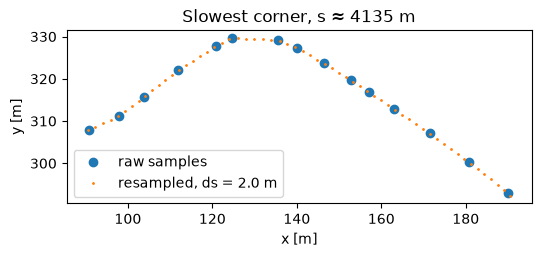

In [49]:
# =================================
# Plotting the slowest corner to have a look
# =================================

i_slow = tel['Speed'].idxmin()                  # row label of the minimum speed
s_c = tel.loc[i_slow, 'Distance']               # distance at that point
print('min speed:', tel.loc[i_slow, 'Speed'], 'km/h at s ≈', round(s_c), 'm')

win = 60                                       

m_raw = (s > s_c - win) & (s < s_c + win)
m_u   = (s_u > s_c - win) & (s_u < s_c + win)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(x[m_raw], y[m_raw], 'o', label='raw samples')
ax.plot(x_u[m_u], y_u[m_u], '.', markersize=2, label=f'resampled, ds = {ds} m')
ax.set_aspect('equal')
ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
ax.set_title(f'Slowest corner, s ≈ {s_c:.0f} m')
ax.legend()
plt.show()

It is noted that there might be a missing data point at the apex of the turn, which is likely the final chicane. There might be a missing data point, it is suspicious because at 84 km/h ≈ 23 m/s with samples about 0.25 s apart it 6 m roughly is expected between samples.

In [50]:
# =================================
# Creating a moving average function for smoothing
# =================================

def curvature(x, y, ds):
    """Signed curvature [1/m] of a path sampled at uniform spacing ds."""
    dx  = np.gradient(x, ds)
    dy  = np.gradient(y, ds)
    ddx = np.gradient(dx, ds)
    ddy = np.gradient(dy, ds)
    return (dx * ddy - dy * ddx) / (dx**2 + dy**2)**1.5

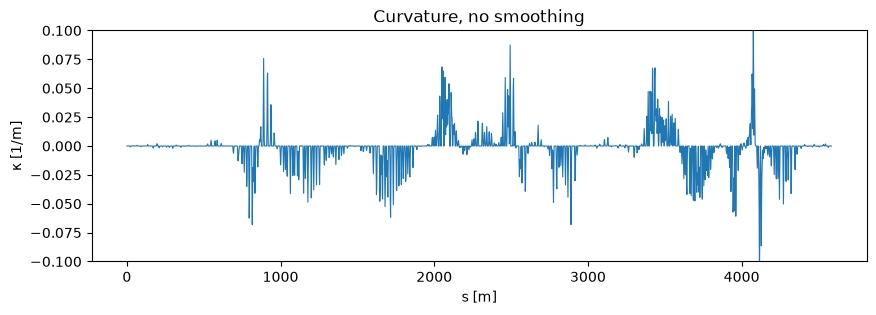

In [51]:
# =================================
# Curvature with no smoothing
# =================================

k_raw = curvature(x_u, y_u, ds)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(s_u, k_raw, lw=0.8)
ax.set_ylim(-0.1, 0.1)                 # ±0.1 1/m = 10 m radius
ax.set_xlabel('s [m]'); ax.set_ylabel('κ [1/m]')
ax.set_title('Curvature, no smoothing')
plt.show()

 10 m window: peak |κ| at slowest corner = 0.0619 1/m  →  r = 16.1 m
 30 m window: peak |κ| at slowest corner = 0.0403 1/m  →  r = 24.8 m
 60 m window: peak |κ| at slowest corner = 0.0252 1/m  →  r = 39.7 m


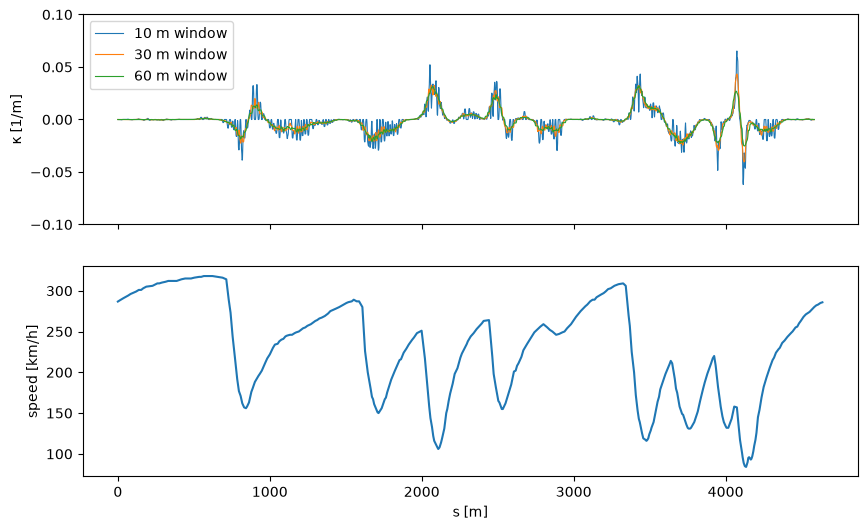

In [52]:
# =================================
# Moving average 
# =================================

from scipy.ndimage import uniform_filter1d

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

near = (s_u > s_c - 50) & (s_u < s_c + 50)     # ±50 m around the slowest corner

for w in [10, 30, 60]:                         # window width [m]
    n = int(w / ds)                            # window width [points]
    xs = uniform_filter1d(x_u, size=n, mode='nearest')
    ys = uniform_filter1d(y_u, size=n, mode='nearest')
    k = curvature(xs, ys, ds)
    ax1.plot(s_u, k, lw=0.8, label=f'{w} m window')
    k_peak = np.abs(k[near]).max()
    print(f'{w:>3} m window: peak |κ| at slowest corner = {k_peak:.4f} 1/m  →  r = {1/k_peak:.1f} m')

ax1.set_ylim(-0.1, 0.1)
ax1.set_ylabel('κ [1/m]'); ax1.legend()
ax2.plot(tel['Distance'], tel['Speed'])
ax2.set_xlabel('s [m]'); ax2.set_ylabel('speed [km/h]')
plt.show()

Moving average           noise (RMS κ on straight) = 0.00014 1/m   chicane radius =  29.5 m
Savitzky–Golay (cubic)   noise (RMS κ on straight) = 0.00024 1/m   chicane radius =  20.8 m
Butterworth + filtfilt   noise (RMS κ on straight) = 0.00022 1/m   chicane radius =  21.9 m


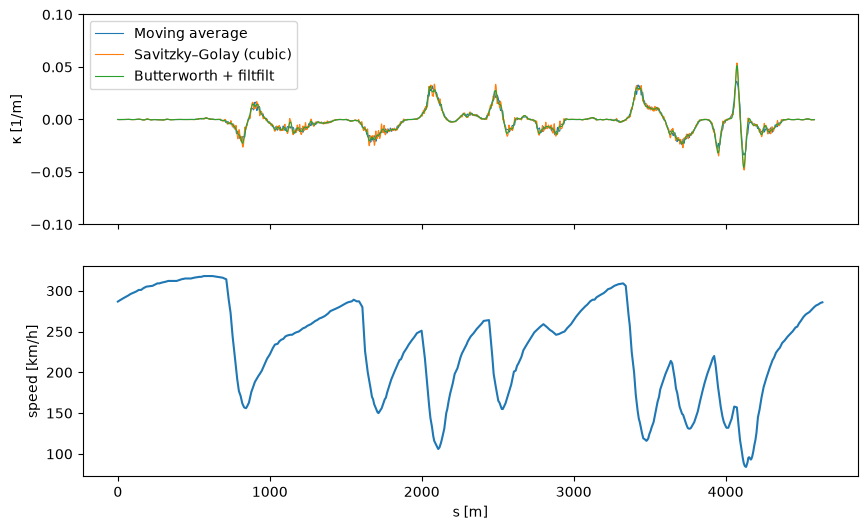

In [53]:
# =================================
# Comparing 3 different filter methods
# =================================

from scipy.signal import savgol_filter, butter, filtfilt

L = 40                                    # smoothing length scale [m]

n_ma = int(L / ds)                        # moving-average width [points]
n_sg = (int(L / ds) // 2) * 2 + 1         # Savitzky–Golay window: must be odd
b, a = butter(4, 1 / L, fs=1 / ds)        # 4th-order low-pass, cut-off 1/L cycles per metre

methods = {
    'Moving average':         (uniform_filter1d(x_u, n_ma, mode='nearest'),
                               uniform_filter1d(y_u, n_ma, mode='nearest')),
    'Savitzky–Golay (cubic)': (savgol_filter(x_u, n_sg, 3),
                               savgol_filter(y_u, n_sg, 3)),
    'Butterworth + filtfilt': (filtfilt(b, a, x_u),
                               filtfilt(b, a, y_u)),
}

straight = (s_u > 100) & (s_u < 500)      # main straight: true κ ≈ 0
near = (s_u > s_c - 50) & (s_u < s_c + 50)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for name, (xs, ys) in methods.items():
    k = curvature(xs, ys, ds)
    noise = np.sqrt(np.mean(k[straight]**2))
    r_min = 1 / np.abs(k[near]).max()
    print(f'{name:<24} noise (RMS κ on straight) = {noise:.5f} 1/m   chicane radius = {r_min:5.1f} m')
    ax1.plot(s_u, k, lw=0.8, label=name)

ax1.set_ylim(-0.1, 0.1); ax1.set_ylabel('κ [1/m]'); ax1.legend()
ax2.plot(tel['Distance'], tel['Speed'])
ax2.set_xlabel('s [m]'); ax2.set_ylabel('speed [km/h]')
plt.show()

In [54]:
# =================================
# Sweep L with a better metric
# This was rerun after using my own grid in the following cell
# =================================

turn3 = (s_u > 1100) & (s_u < 1450)        # long, near-constant-radius corner
near  = (s_u > s_c - 50) & (s_u < s_c + 50)

print(f"{'L [m]':>5}  {'method':<24} {'T3 std κ [1/m]':>15} {'chicane r [m]':>14}")
for L in [30, 40, 60, 80]:
    n_ma = int(L / ds)
    n_sg = (int(L / ds) // 2) * 2 + 1
    b, a = butter(4, 1 / L, fs=1 / ds)
    methods = {
        'Moving average':         (uniform_filter1d(x_u, n_ma, mode='nearest'),
                                   uniform_filter1d(y_u, n_ma, mode='nearest')),
        'Savitzky–Golay (cubic)': (savgol_filter(x_u, n_sg, 3), savgol_filter(y_u, n_sg, 3)),
        'Butterworth + filtfilt': (filtfilt(b, a, x_u), filtfilt(b, a, y_u)),
    }
    for name, (xs, ys) in methods.items():
        k = curvature(xs, ys, ds)
        t3_std = np.std(k[turn3])
        r_min = 1 / np.abs(k[near]).max()
        print(f"{L:>5}  {name:<24} {t3_std:>15.5f} {r_min:>14.1f}")
    print()

L [m]  method                    T3 std κ [1/m]  chicane r [m]
   30  Moving average                   0.00352           24.8
   30  Savitzky–Golay (cubic)           0.00477           18.9
   30  Butterworth + filtfilt           0.00418           20.4

   40  Moving average                   0.00331           29.5
   40  Savitzky–Golay (cubic)           0.00408           20.8
   40  Butterworth + filtfilt           0.00362           21.9

   60  Moving average                   0.00318           39.7
   60  Savitzky–Golay (cubic)           0.00349           24.3
   60  Butterworth + filtfilt           0.00323           22.6

   80  Moving average                   0.00314           51.4
   80  Savitzky–Golay (cubic)           0.00323           24.8
   80  Butterworth + filtfilt           0.00316           27.1



In [55]:
# =================================
# Speed on my own s grid
# =================================

print('s ends at:', s[-1], '  Distance ends at:', tel['Distance'].iloc[-1])

t_pos = pos['Time'].dt.total_seconds().to_numpy()       # time of each raw position sample [s]
t_tel = tel['Time'].dt.total_seconds().to_numpy()
v_pos = np.interp(t_pos, t_tel, tel['Speed'].to_numpy()) / 3.6   # speed at each position sample [m/s]
v_u = np.interp(s_u, s, v_pos)                          # speed on the uniform grid [m/s]

s_c = s_u[np.argmin(v_u)]                               # slowest point, now in YOUR s
print('slowest point at s =', round(s_c), 'm')

s ends at: 4585.036019287911   Distance ends at: 4636.771676129172
slowest point at s = 4092 m


peak implied lateral acceleration: 6.2 g at s = 2780 m, v = 258 km/h


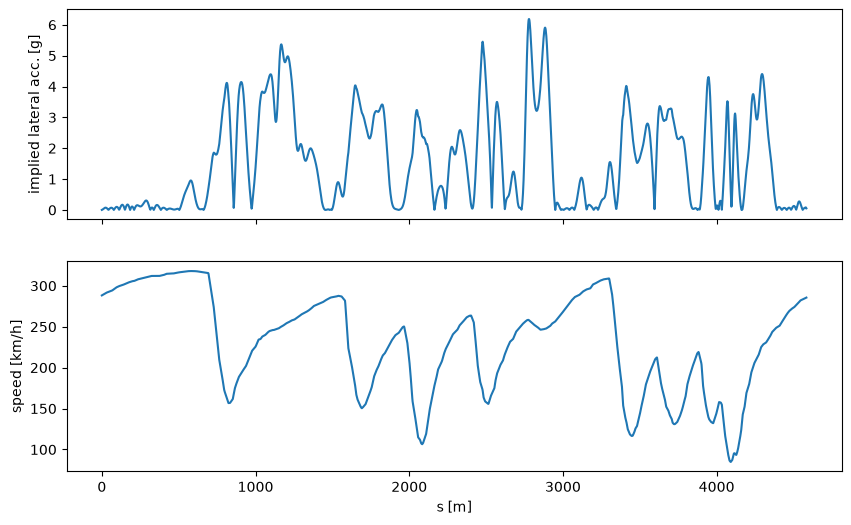

In [56]:
# =================================
# Lateral acceleration sanity check
# =================================

b, a = butter(4, 1 / 60, fs=1 / ds)            # chosen filter: Butterworth, L = 60 m
x_s = filtfilt(b, a, x_u)
y_s = filtfilt(b, a, y_u)
k_s = curvature(x_s, y_s, ds)

a_lat_g = v_u**2 * np.abs(k_s) / 9.81          # implied lateral acceleration [g]

i_max = np.argmax(a_lat_g)
print(f'peak implied lateral acceleration: {a_lat_g[i_max]:.1f} g at s = {s_u[i_max]:.0f} m, '
      f'v = {v_u[i_max]*3.6:.0f} km/h')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(s_u, a_lat_g)
ax1.set_ylabel('implied lateral acc. [g]')
ax2.plot(s_u, v_u * 3.6)
ax2.set_xlabel('s [m]'); ax2.set_ylabel('speed [km/h]')

plt.show()

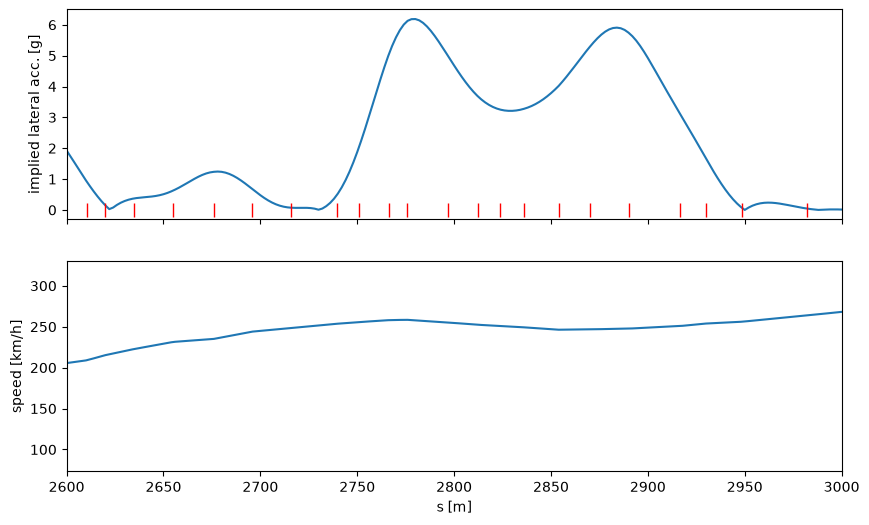

In [57]:
# =================================================================
# Checking whether the two-hump shape in T9 comes from sample spacing
#
# T3 and T9 have two humps. A single apex corner taken
# at constant speed shouldn’t have its lateral load halve 
# in the middle. I feel it is likely because the smoothing 
# length is fixed in metres, but the sample spacing grows 
# with speed, so the fast corners are the least well smoothed.
# =================================================================

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(s_u, a_lat_g)
ax1.set_ylabel('implied lateral acc. [g]')
ax2.plot(s_u, v_u * 3.6)
ax2.set_xlabel('s [m]'); ax2.set_ylabel('speed [km/h]')

ax1.plot(s, np.zeros_like(s), '|', color='red', markersize=10)   # raw sample positions
ax1.set_xlim(2600, 3000)

plt.show()

In [58]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('..')
from src.track import track_geometry

geo = track_geometry(lap)
print('peak a_lat:', geo['a_lat_g'].max().round(1), 'g')
geo.head()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
peak a_lat: 6.2 g


,s,x,y,kappa,r,v,a_lat_g
0,0.0,75.828888,-57.340361,-0.000003,10000.0,80.065973,0.002083
1,2.0,74.687709,-59.145544,-0.000007,10000.0,80.128024,0.004814
2,4.0,73.550211,-60.944850,-0.000017,10000.0,80.190074,0.011110
3,6.0,72.418878,-62.734263,-0.000028,10000.0,80.252125,0.018521
4,8.0,71.295489,-64.510877,-0.000040,10000.0,80.314175,0.026435


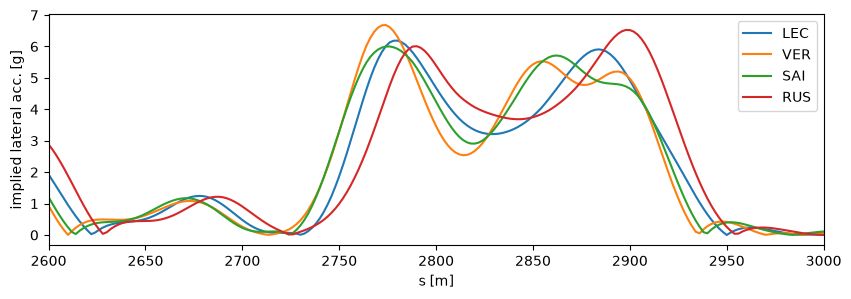

In [63]:
# =================================
# The cross lap test
# =================================

fig, ax = plt.subplots(figsize=(10, 3))
for drv in ['LEC', 'VER', 'SAI', 'RUS']:
    lap_d = session.laps.pick_drivers(drv).pick_fastest()
    g = track_geometry(lap_d)
    ax.plot(g['s'], g['a_lat_g'], label=drv)
ax.set_xlim(2600, 3000)
ax.set_xlabel('s [m]'); ax.set_ylabel('implied lateral acc. [g]')
ax.legend()
plt.show()
fig.savefig('../figures/02_T9_cross_driver.png', dpi=150, bbox_inches='tight')

In [64]:
fig.savefig('../figures/02_name.png', dpi=150, bbox_inches='tight')

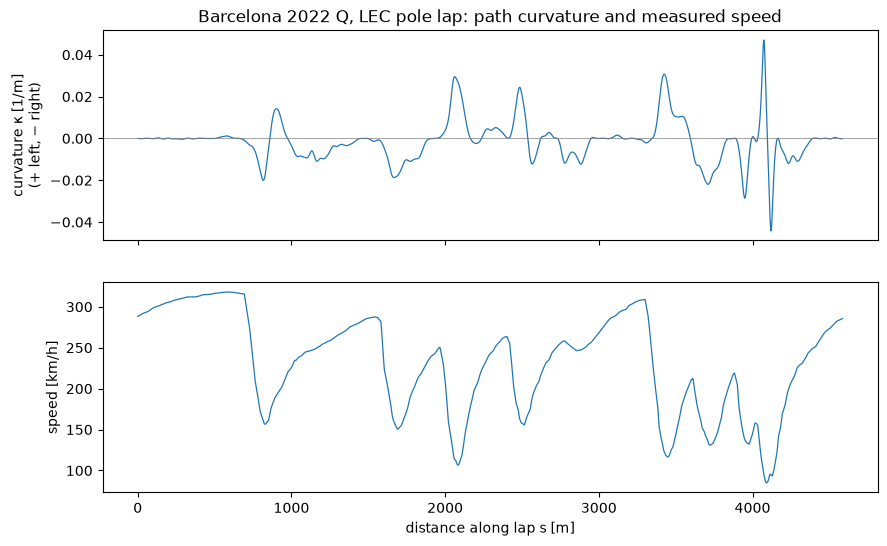

In [65]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(geo['s'], geo['kappa'], lw=0.9)
ax1.axhline(0, color='grey', lw=0.5)
ax1.set_ylabel('curvature κ [1/m]\n(+ left, − right)')
ax2.plot(geo['s'], geo['v'] * 3.6, lw=0.9)
ax2.set_xlabel('distance along lap s [m]'); ax2.set_ylabel('speed [km/h]')
ax1.set_title('Barcelona 2022 Q, LEC pole lap: path curvature and measured speed')
fig.savefig('../figures/02_curvature_speed.png', dpi=150, bbox_inches='tight')
plt.show()

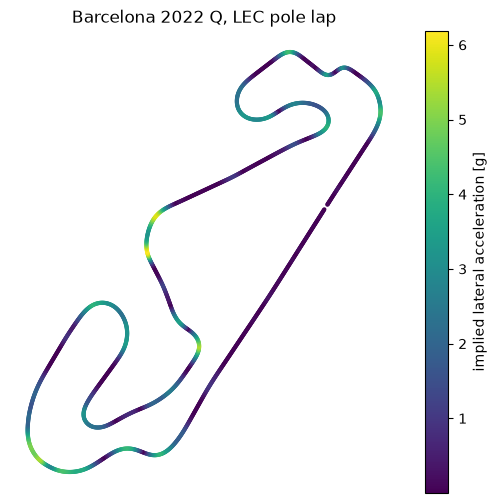

In [66]:
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(geo['x'], geo['y'], c=geo['a_lat_g'], s=4, cmap='viridis')
fig.colorbar(sc, ax=ax, label='implied lateral acceleration [g]')
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('Barcelona 2022 Q, LEC pole lap')
fig.savefig('../figures/02_track_map_lateral_g.png', dpi=150, bbox_inches='tight')
plt.show()